# Assignment 4 ? Part 2 ? MsPacMan Q-table

This variant adds tabular Q-learning to the original MsPacMan experiment. It reuses the original environment, scoring, seeds and evaluation pipeline. The task succeeds at 2,000 raw Atari points.

**Run locally.** Open with a Python 3.12 kernel. The configuration cell defaults to Q-table only. Add DQN or PPO to `ALGORITHMS` to rerun them in the same experiment. Run cells in order. Training and final evaluation are separate cells. Each new timestamped result folder appears in the dashboard after you refresh its run list.

| Settings | Action repeat probability | Starting maze | Reward per agent step | Training |
|:--|--:|:--|:--|:--|
| A · Predictable | 0% | Original | +1 on success, 0 otherwise | Fresh agents |
| B · Uncertain | 25% | Original | +1 on success, 0 otherwise | Fresh agents |
| C · Changed incentives | 25% | Original | A step penalty of 0.0005, including the final step, plus +1 on success | Fresh agents |
| D · Transfer | 25% | Alternate | +1 on success, 0 otherwise | Evaluate the frozen B agents |

A Q-table is useful only if the agent revisits its keys. This baseline groups RAM positions into 12-unit bins and adds the current direction and relative sector of the nearest active ghost within 24 Manhattan units. As in the original Q-learning teaching API, it uses a dictionary keyed by discrete states and one TD update per transition.

The table does not encode the pellet layout, exact positions, score, or the maze ID. Different situations may share a key. Reused keys can occur on the alternate maze, but the same coordinates can correspond to different corridors. The Q-table receives RAM-derived features, while DQN and PPO receive stacked pixels. The comparison therefore changes both the learning algorithm and the state representation.

RAM field definitions follow [OCAtari?s MsPacman extractor](https://github.com/k4ntz/OC_Atari/blob/master/ocatari/ram/mspacman.py#L168-L201).

In [1]:
%pip install "gymnasium[atari]==1.2.3" "ale-py==0.11.2" "opencv-python-headless>=4.10,<5" "torch==2.7.1" "pandas>=2.2,<3" "matplotlib>=3.9,<4" "joblib>=1.4,<2"

  Using cached opencv_python_headless-4.14.0.94-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached pytz-2026.6-py2.py3-none-any.whl.metadata (22 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached markupsafe-3.0.4-cp313-cp31


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from functools import partial
from importlib.metadata import version
from pathlib import Path
from time import perf_counter
import gzip
import json
import os
import platform

import ale_py
import gymnasium as gym
from gymnasium.wrappers import FrameStackObservation, RecordEpisodeStatistics, ResizeObservation, TimeLimit
from IPython.display import display
from joblib import Parallel, delayed, parallel_config
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.distributions import Categorical

gym.register_envs(ale_py)

ENV_ID = "ALE/MsPacman-v5"
SUCCESS_POINTS = 2_000
MAX_EPISODE_STEPS = 1_024
FRAME_SKIP = 4
OBS_SHAPE = (4, 42, 42)
TRAINING_SEEDS = (42, 43, 44)
MONITOR_SEEDS = tuple(range(100_000, 100_008))
TEST_SEEDS = tuple(range(200_000, 200_200))
INTERACTION_BUDGET = 16_384
CHECKPOINT_EVERY = 4_096
TRAIN_ENVS = 8
EVAL_ENVS = 24
EVAL_WORKERS = min(4, os.cpu_count() or 1)
TORCH_THREADS = 1
# Add "DQN" or "PPO" here to rerun the original baselines.
ALGORITHMS = ("Q-table",)
GAMMA = 0.99
Q_TABLE = dict(alpha=0.15, epsilon_start=1.0, epsilon_end=0.10,
               exploration_steps=12_288, position_bin=12, ghost_radius=24)
DQN = dict(lr=2.5e-4, replay_size=8_192, warmup=512, batch_size=32,
           epsilon_start=1.0, epsilon_end=0.10, exploration_steps=12_288,
           target_sync=512, max_grad_norm=10.0)
PPO = dict(lr=2.5e-4, rollout_steps=64, gae_lambda=0.95, clip=0.20,
           epochs=4, batch_size=64, entropy_coef=0.01, value_coef=0.5,
           max_grad_norm=0.5)
DEVICE = torch.device("cpu")
torch.set_num_threads(TORCH_THREADS)


@dataclass(frozen=True)
class Setting:
    sticky: float
    step_penalty: float = 0.0
    maze: int = 0


SETTINGS = {"A": Setting(0.0), "B": Setting(0.25),
            "C": Setting(0.25, 0.0005), "D": Setting(0.25, maze=1)}
PARAMS = {"Q-table": Q_TABLE, "DQN": DQN, "PPO": PPO}
POLICY_MODES = {"Q-table": "greedy Q-table (current direction on ties when available)",
                "DQN": "greedy Q (first action on ties)", "PPO": "sampled categorical"}
assert ALGORITHMS and len(ALGORITHMS) == len(set(ALGORITHMS)) and set(ALGORITHMS) <= PARAMS.keys()
assert TRAIN_ENVS > 0 and CHECKPOINT_EVERY > 0 and INTERACTION_BUDGET > 0
assert CHECKPOINT_EVERY % TRAIN_ENVS == 0

assert set(TRAINING_SEEDS).isdisjoint(MONITOR_SEEDS + TEST_SEEDS)
assert set(MONITOR_SEEDS).isdisjoint(TEST_SEEDS)
assert len(TEST_SEEDS) >= 200
assert INTERACTION_BUDGET % CHECKPOINT_EVERY == 0
if "PPO" in ALGORITHMS:
    assert CHECKPOINT_EVERY % (TRAIN_ENVS * PPO["rollout_steps"]) == 0

## Environment and experimental controls

In A the emulator uses fixed frame skip, no sticky actions, and a fixed start. B changes only ALE's probability of repeating the previous action. In C a successful 600-step episode earns 0.70 while a failed 600-step episode earns −0.30. Compare B and C on goal attainment, failure, raw score, and steps by outcome.

For D, the reset selects the alternate layout already present in the MsPacman ROM by setting ALE RAM byte 0 to 1. Both starts advance the same one NOOP decision at reset to render the maze. Reset preparation does not count against the agent's interactions. Everything after reset uses the normal game mechanics with B's sticky-action and reward settings. The reset changes the starting level, so this tests transfer to the alternate level as a whole. Shared convolution filters may reuse visual cues for corridors, pellets and ghosts across positions. Layout changes and the smaller grayscale images can still affect performance. A tabular ID for the exact image stack would provide no such feature sharing.

Sources for the environment are the [ALE MsPacman documentation](https://ale.farama.org/environments/ms_pacman/), the [Gymnasium observation wrappers](https://gymnasium.farama.org/api/wrappers/observation_wrappers/), and the [HackAtari level-selection code](https://github.com/k4ntz/HackAtari/blob/master/hackatari/games/mspacman.py#L61-L77).

Wall/maze pixels that differ between B and D: 5,728


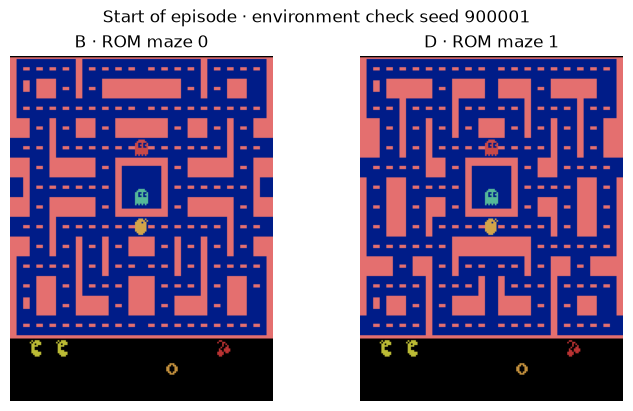

In [3]:
class MazeStart(gym.Wrapper):
    """Select the ROM's starting maze before the initial frame is stacked."""

    def __init__(self, env, maze):
        super().__init__(env)
        self.maze = maze
        self.ale = self.unwrapped.ale
        self.noop = self.unwrapped.get_action_meanings().index("NOOP")

    def reset(self, *, seed=None, options=None):
        self.env.reset(seed=seed, options=options)
        if self.maze != 0:
            self.ale.setRAM(0, self.maze)
        observation, points, terminated, truncated, info = self.env.step(self.noop)
        if points != 0 or terminated or truncated or self.ale.getRAM()[0] != self.maze:
            raise RuntimeError("Unexpected MsPacman state during maze reset.")
        return observation, info


class ScoreGoal(gym.Wrapper):
    def __init__(self, env, setting):
        super().__init__(env)
        self.setting = setting
        self.ale = self.unwrapped.ale

    def reset(self, **kwargs):
        self.score = 0.0
        return self.env.reset(**kwargs)

    def step(self, action):
        obs, points, game_over, timeout, info = self.env.step(action)
        self.score += float(points)
        success = self.score >= SUCCESS_POINTS
        maze_exit = int(self.ale.getRAM()[0]) != self.setting.maze
        terminated = bool(success or game_over or maze_exit)
        truncated = bool(timeout and not terminated)
        outcome = ("success" if success else "game_over" if game_over else
                   "maze_exit" if maze_exit else "timeout" if truncated else "in_progress")
        reward = float(success) - self.setting.step_penalty
        info.update(raw_points=float(points), raw_score=self.score, outcome=outcome)
        return obs, reward, terminated, truncated, info


def tabular_state(ram):
    """Encode coarse player position, heading and the nearest nearby ghost."""
    x, y = int(ram[10]), int(ram[16])
    heading = int(ram[56]) & 3
    sector = 9
    if ram[47] > 0:
        ghosts = range(1 + min(int(ram[19]), 3))
        offsets = [(int(ram[6 + i]) - x, int(ram[12 + i]) - y) for i in ghosts]
        dx, dy = min(offsets, key=lambda offset: abs(offset[0]) + abs(offset[1]))
        if abs(dx) + abs(dy) <= Q_TABLE["ghost_radius"]:
            sx = int(dx > 0) - int(dx < 0)
            sy = int(dy > 0) - int(dy < 0)
            sector = (sx + 1) * 3 + sy + 1
    position_bin = Q_TABLE["position_bin"]
    return x // position_bin, y // position_bin, heading, sector


class TabularObservation(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)
        positions = 255 // Q_TABLE["position_bin"] + 1
        self.observation_space = gym.spaces.MultiDiscrete([positions, positions, 4, 10])

    def observation(self, observation):
        return np.asarray(tabular_state(self.unwrapped.ale.getRAM()), dtype=np.int64)


def build_environment(setting_name, algorithm=None):
    setting = SETTINGS[setting_name]
    env = gym.make(ENV_ID, obs_type="grayscale", frameskip=FRAME_SKIP,
                   repeat_action_probability=setting.sticky, full_action_space=False)
    env = MazeStart(env, setting.maze)
    env = ResizeObservation(env, OBS_SHAPE[1:])
    env = FrameStackObservation(env, stack_size=OBS_SHAPE[0])
    env = TimeLimit(env, max_episode_steps=MAX_EPISODE_STEPS)
    env = RecordEpisodeStatistics(ScoreGoal(env, setting))
    return TabularObservation(env) if algorithm == "Q-table" else env


def check_environment():
    images, shapes, actions = {}, {}, {}
    for name in ("A", "B", "C", "D"):
        with build_environment(name) as env:
            observation, _ = env.reset(seed=900_001)
            assert env.observation_space.contains(observation)
            shapes[name] = observation.shape
            actions[name] = env.unwrapped.get_action_meanings()
            images[name] = env.unwrapped.ale.getScreenRGB()
            _, reward, terminated, truncated, info = env.step(0)
            assert not (terminated or truncated) and info["raw_score"] == 0
            assert reward == -SETTINGS[name].step_penalty
    assert all(shape == OBS_SHAPE for shape in shapes.values())
    assert all(action_list == actions["A"] for action_list in actions.values())
    assert np.array_equal(images["A"], images["B"])
    assert np.array_equal(images["B"], images["C"])
    wall_color = (228, 111, 111)
    walls = {name: np.all(rgb[:170] == wall_color, axis=-1) for name, rgb in images.items()}
    assert walls["B"].any() and walls["D"].any()
    print(f"Wall/maze pixels that differ between B and D: {np.sum(walls['B'] != walls['D']):,}")
    fig, axes = plt.subplots(1, 2, figsize=(7, 4), layout="constrained")
    for ax, name in zip(axes, ("B", "D")):
        ax.imshow(images[name]); ax.set_title(f"{name} · ROM maze {SETTINGS[name].maze}")
        ax.axis("off")
    fig.suptitle("Start of episode · environment check seed 900001")
    plt.show()
    return actions["A"]


ACTION_NAMES = check_environment()

## Training and evaluation protocol

The default interaction budget is 16,384 per trained agent, with the same three training seeds as the original experiment. Q-table uses epsilon-greedy exploration during training. It evaluates greedily and prefers the current direction if that action ties for the highest Q-value. An unseen state uses zero values. Evaluation never inserts new table rows. DQN is greedy with first-action tie breaking, and PPO samples its categorical policy.

Monitor on eight separate seeds at zero interactions and every 4,096 interactions. Evaluate the final checkpoint on 200 held-out episodes per agent and setting. Evaluate the exact same frozen B agents on D. There is no hyperparameter search. The figures average across training seeds and show one sample standard deviation, with no smoothing.

Q-table evaluation also reports the fraction of decisions whose state key was present in the training table. This measures key reuse, including keys with zero Q-values.

In [4]:
class AtariEncoder(nn.Sequential):
    def __init__(self):
        super().__init__(nn.Conv2d(4, 16, 6, stride=4), nn.ReLU(),
                         nn.Conv2d(16, 32, 4, stride=2), nn.ReLU(), nn.Flatten(),
                         nn.Linear(32 * 4 * 4, 128), nn.ReLU())

    def forward(self, pixels):
        return super().forward(pixels.float() / 255.0)


class AtariQNetwork(nn.Sequential):
    def __init__(self, action_count):
        super().__init__(AtariEncoder(), nn.Linear(128, action_count))


class AtariActorCritic(nn.Module):
    def __init__(self, action_count):
        super().__init__()
        self.encoder = AtariEncoder()
        self.actor = nn.Linear(128, action_count)
        self.critic = nn.Linear(128, 1)
        nn.init.orthogonal_(self.actor.weight, gain=0.01)
        nn.init.zeros_(self.actor.bias)
        nn.init.orthogonal_(self.critic.weight)
        nn.init.zeros_(self.critic.bias)

    def forward(self, pixels):
        features = self.encoder(pixels)
        return self.actor(features), self.critic(features).squeeze(-1)


def tensor(array):
    return torch.as_tensor(array, device=DEVICE)


class AtariReplayBuffer:
    """Store complete uint8 stacks so interleaved environments remain independent."""

    def __init__(self, capacity, rng):
        self.rng = rng
        self.capacity = capacity
        self.size = self.position = 0
        self.states = np.empty((capacity, *OBS_SHAPE), dtype=np.uint8)
        self.next_states = np.empty_like(self.states)
        self.actions = np.empty(capacity, dtype=np.int64)
        self.rewards = np.empty(capacity, dtype=np.float32)
        self.terminals = np.empty(capacity, dtype=bool)

    def add(self, states, actions, rewards, next_states, terminals):
        indices = (self.position + np.arange(len(actions))) % self.capacity
        self.states[indices] = states
        self.actions[indices] = actions
        self.rewards[indices] = rewards
        self.next_states[indices] = next_states
        self.terminals[indices] = terminals
        self.position = (self.position + len(indices)) % self.capacity
        self.size = min(self.size + len(indices), self.capacity)

    def sample(self, batch_size):
        indices = self.rng.integers(self.size, size=batch_size)
        return tuple(tensor(array[indices]) for array in
                     (self.states, self.actions, self.rewards, self.next_states, self.terminals))


class TrainingBatch:
    def __init__(self, setting, seed, algorithm):
        self.env = gym.vector.SyncVectorEnv(
            [partial(build_environment, setting, algorithm) for _ in range(TRAIN_ENVS)],
            autoreset_mode=gym.vector.AutoresetMode.DISABLED,
        )
        env_seeds = [seed * 1_000 + i for i in range(TRAIN_ENVS)]
        self.obs, _ = self.env.reset(seed=env_seeds)
        self.actions = self.env.single_action_space.n
        self.interactions = 0
        self.episodes = []

    def step(self, actions):
        next_obs, rewards, terminated, truncated, info = self.env.step(actions)
        self.interactions += TRAIN_ENVS
        done = terminated | truncated
        for i in np.flatnonzero(done):
            self.episodes.append(dict(interactions=self.interactions, env_index=int(i),
                                      episode_return=float(info["episode"]["r"][i]),
                                      length=int(info["episode"]["l"][i]),
                                      raw_score=float(info["raw_score"][i]),
                                      outcome=str(info["outcome"][i])))
        if done.any():
            self.obs, _ = self.env.reset(options={"reset_mask": done})
        else:
            self.obs = next_obs
        return next_obs, rewards, terminated, done

In [5]:
class TabularQModel:
    def __init__(self, action_count):
        self.zero = np.zeros(action_count, dtype=np.float64)
        self.q = {}

    def values(self, state):
        return self.q.get(tuple(state), self.zero)

    def greedy(self, state):
        values = self.values(state)
        best = int(values.argmax())
        forward = (1, 2, 4, 3)[state[2]]  # UP, RIGHT, DOWN, LEFT in the ALE minimal action space.
        return forward if values[forward] == values[best] else best

    def save(self, path):
        keys = np.asarray(list(self.q), dtype=np.int16).reshape(-1, 4)
        values = np.asarray(list(self.q.values()), dtype=np.float64).reshape(-1, len(self.zero))
        np.savez_compressed(path, keys=keys, values=values)


class TabularQTrainer:
    def __init__(self, action_count, seed):
        self.model = TabularQModel(action_count)
        self.rng = np.random.default_rng(seed)
        self.updates = 0

    def train_until(self, batch, stop):
        cfg = Q_TABLE
        while batch.interactions < stop:
            observations = batch.obs
            epsilon = np.interp(batch.interactions, [0, cfg["exploration_steps"]],
                                [cfg["epsilon_start"], cfg["epsilon_end"]])
            actions = np.array([self.rng.integers(batch.actions) if self.rng.random() < epsilon
                                else self.model.greedy(state) for state in observations])
            next_obs, rewards, terminated, _ = batch.step(actions)
            for state, action, reward, next_state, terminal in zip(observations, actions, rewards, next_obs, terminated):
                key = tuple(state)
                if key not in self.model.q:
                    self.model.q[key] = self.model.zero.copy()
                values = self.model.q[key]
                future = 0.0 if terminal else self.model.values(next_state).max()
                values[action] += cfg["alpha"] * (reward + GAMMA * future - values[action])
                self.updates += 1


class DQNTrainer:
    def __init__(self, action_count, seed):
        self.rng = np.random.default_rng(seed)
        self.model = AtariQNetwork(action_count).to(DEVICE)
        self.target = AtariQNetwork(action_count).to(DEVICE).eval()
        self.target.load_state_dict(self.model.state_dict())
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=DQN["lr"])
        self.replay = AtariReplayBuffer(DQN["replay_size"], self.rng)
        self.updates = 0

    def train_until(self, batch, stop):
        self.model.train()
        while batch.interactions < stop:
            observation = batch.obs
            epsilon = np.interp(batch.interactions, [0, DQN["exploration_steps"]],
                                [DQN["epsilon_start"], DQN["epsilon_end"]])
            with torch.no_grad():
                greedy = self.model(tensor(observation)).argmax(dim=1).cpu().numpy()
            explore = self.rng.random(TRAIN_ENVS) < epsilon
            actions = np.where(explore, self.rng.integers(batch.actions, size=TRAIN_ENVS), greedy)
            next_obs, rewards, terminated, _ = batch.step(actions)
            self.replay.add(observation, actions, rewards, next_obs, terminated)
            if batch.interactions >= DQN["warmup"]:
                states, acts, returns, successors, terminals = self.replay.sample(DQN["batch_size"])
                estimate = self.model(states).gather(1, acts[:, None]).squeeze(1)
                with torch.no_grad():
                    target = returns + GAMMA * (~terminals) * self.target(successors).amax(dim=1)
                loss = F.smooth_l1_loss(estimate, target)
                self.optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(self.model.parameters(), DQN["max_grad_norm"])
                self.optimizer.step()
                self.updates += 1
            if batch.interactions % DQN["target_sync"] == 0:
                self.target.load_state_dict(self.model.state_dict())


def gae_targets(rewards, values, next_values, terminated, done):
    """Bootstrap at time limits, but stop GAE at any episode boundary."""
    advantages = torch.empty_like(values)
    gae = torch.zeros_like(values[0])
    for t in range(len(values) - 1, -1, -1):
        delta = rewards[t] + GAMMA * (~terminated[t]) * next_values[t] - values[t]
        gae = delta + GAMMA * PPO["gae_lambda"] * (~done[t]) * gae
        advantages[t] = gae
    return advantages, advantages + values


class PPOTrainer:
    def __init__(self, action_count, seed):
        self.rng = np.random.default_rng(seed)
        self.model = AtariActorCritic(action_count).to(DEVICE)
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=PPO["lr"], eps=1e-5)
        self.updates = 0

    @torch.no_grad()
    def collect(self, batch):
        rollout = []
        for _ in range(PPO["rollout_steps"]):
            states = tensor(batch.obs)
            logits, values = self.model(states)
            distribution = Categorical(logits=logits)
            actions = distribution.sample()
            next_obs, rewards, terminated, done = batch.step(actions.cpu().numpy())
            _, next_values = self.model(tensor(next_obs))
            rollout.append((states, actions, distribution.log_prob(actions), values,
                            next_values, tensor(rewards.astype(np.float32)),
                            tensor(terminated), tensor(done)))
        states, actions, logp, values, next_values, rewards, term, done = map(torch.stack, zip(*rollout))
        advantages, targets = gae_targets(rewards, values, next_values, term, done)
        advantages = (advantages - advantages.mean()) / (advantages.std(unbiased=False) + 1e-8)
        return tuple(x.flatten(0, 1) for x in (states, actions, logp, advantages, targets))

    def train_until(self, batch, stop):
        self.model.train()
        while batch.interactions < stop:
            states, actions, old_logp, advantages, targets = self.collect(batch)
            for _ in range(PPO["epochs"]):
                for indices in np.split(self.rng.permutation(len(actions)), len(actions) // PPO["batch_size"]):
                    logits, values = self.model(states[indices])
                    policy = Categorical(logits=logits)
                    ratio = (policy.log_prob(actions[indices]) - old_logp[indices]).exp()
                    adv = advantages[indices]
                    clipped = ratio.clamp(1 - PPO["clip"], 1 + PPO["clip"])
                    actor_loss = -torch.minimum(ratio * adv, clipped * adv).mean()
                    value_loss = F.mse_loss(values, targets[indices])
                    loss = actor_loss + PPO["value_coef"] * value_loss - PPO["entropy_coef"] * policy.entropy().mean()
                    self.optimizer.zero_grad(set_to_none=True)
                    loss.backward()
                    nn.utils.clip_grad_norm_(self.model.parameters(), PPO["max_grad_norm"])
                    self.optimizer.step()
                    self.updates += 1

## Frozen evaluation and episode records

Evaluation runs in batches for inference. Each episode has its own emulator seed and a policy RNG seeded independently from the training RNG. Final evaluation also records the chosen actions for every episode, so a specific episode can be replayed from its seed and inspected with the stored checkpoint.

In [6]:
@torch.inference_mode()
def evaluate(model, algorithm, setting, seeds, record_actions=False):
    if algorithm != "Q-table":
        model.eval()
    results, traces = [], []
    start = perf_counter()
    envs = [build_environment(setting, algorithm) for _ in range(min(EVAL_ENVS, len(seeds)))]
    try:
        # Separate generators keep PPO's actions reproducible across batch sizes.
        uniforms = [np.random.default_rng([seed, 29]).random(MAX_EPISODE_STEPS) for seed in seeds]
        for offset in range(0, len(seeds), len(envs)):
            batch_seeds = seeds[offset:offset + len(envs)]
            ob = {i: envs[i].reset(seed=seed)[0] for i, seed in enumerate(batch_seeds)}
            action_logs = [[] for _ in batch_seeds]
            seen = np.zeros(len(batch_seeds), dtype=int)
            for step in range(MAX_EPISODE_STEPS):
                if not ob:
                    break
                slots = list(ob)
                if algorithm == "Q-table":
                    actions = [model.greedy(ob[i]) for i in slots]
                    for i in slots:
                        seen[i] += tuple(ob[i]) in model.q
                elif algorithm == "DQN":
                    actions = model(tensor(np.stack(list(ob.values())))).argmax(dim=1).numpy()
                else:
                    logits, _ = model(tensor(np.stack(list(ob.values()))))
                    cdf = logits.softmax(dim=1).cumsum(dim=1).numpy()
                    cdf[:, -1] = 1.0
                    draws = [uniforms[offset + i][step] for i in slots]
                    actions = (np.asarray(draws)[:, None] >= cdf).sum(axis=1)
                for i, action in zip(slots, actions):
                    ob[i], _, terminated, truncated, info = envs[i].step(int(action))
                    if record_actions:
                        action_logs[i].append(int(action))
                    if terminated or truncated:
                        seed = batch_seeds[i]
                        results.append(dict(eval_seed=seed, length=int(info["episode"]["l"]),
                                            episode_return=float(info["episode"]["r"]),
                                            raw_score=float(info["raw_score"]), outcome=info["outcome"]))
                        if algorithm == "Q-table":
                            results[-1]["known_state_steps"] = int(seen[i])
                        if record_actions:
                            traces.append(dict(eval_seed=seed, actions=action_logs[i]))
                        del ob[i]
            assert not ob, "Gymnasium TimeLimit should end every episode in the batch."
    finally:
        for env in envs:
            env.close()
    return sorted(results, key=lambda row: row["eval_seed"]), traces, perf_counter() - start


def load_model(algorithm, path):
    if algorithm == "Q-table":
        model = TabularQModel(len(ACTION_NAMES))
        with np.load(path, allow_pickle=False) as checkpoint:
            model.q = {tuple(key): values.copy() for key, values in
                       zip(checkpoint["keys"], checkpoint["values"], strict=True)}
        return model
    model_class = AtariQNetwork if algorithm == "DQN" else AtariActorCritic
    model = model_class(len(ACTION_NAMES)).to(DEVICE)
    model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=True))
    return model.eval()


def summarize(episodes):
    success = [row["length"] for row in episodes if row["outcome"] == "success"]
    failure = [row["length"] for row in episodes if row["outcome"] != "success"]
    coverage = {}
    if "known_state_steps" in episodes[0]:
        coverage["known_state_rate"] = sum(row["known_state_steps"] for row in episodes) / sum(
            row["length"] for row in episodes)
    return dict(**coverage, episodes=len(episodes), successes=len(success), failures=len(failure),
                success_rate=len(success) / len(episodes), failure_rate=len(failure) / len(episodes),
                mean_return=float(np.mean([row["episode_return"] for row in episodes])),
                mean_raw_score=float(np.mean([row["raw_score"] for row in episodes])),
                success_length=float(np.mean(success)) if success else np.nan,
                failure_length=float(np.mean(failure)) if failure else np.nan,
                eval_interactions=sum(row["length"] for row in episodes))


def run_training(setting, algorithm, seed, output):
    run_id = f"{setting}-{algorithm}-s{seed}"
    folder = output / run_id
    folder.mkdir()
    torch.manual_seed(seed)
    batch = TrainingBatch(setting, seed, algorithm)
    trainer_class = {"Q-table": TabularQTrainer, "DQN": DQNTrainer, "PPO": PPOTrainer}[algorithm]
    trainer = trainer_class(batch.actions, seed)
    training_seconds = 0.0
    curve, monitor_episodes = [], []
    try:
        for interactions in range(0, INTERACTION_BUDGET + 1, CHECKPOINT_EVERY):
            if interactions:
                start = perf_counter()
                trainer.train_until(batch, interactions)
                training_seconds += perf_counter() - start
            assert batch.interactions == interactions
            rows, _, elapsed = evaluate(trainer.model, algorithm, setting, MONITOR_SEEDS)
            monitor_episodes.extend(dict(row, run_id=run_id, interactions=interactions) for row in rows)
            curve.append(dict(run_id=run_id, setting=setting, algorithm=algorithm, train_seed=seed,
                              interactions=interactions, training_seconds=training_seconds,
                              monitor_seconds=elapsed, **summarize(rows)))
        checkpoint = folder / ("q_table.npz" if algorithm == "Q-table" else "model.pt")
        if algorithm == "Q-table":
            trainer.model.save(checkpoint)
        else:
            torch.save(trainer.model.state_dict(), checkpoint)
        pd.DataFrame(monitor_episodes).to_csv(folder / "monitor_episodes.csv", index=False)
        pd.DataFrame(batch.episodes).assign(run_id=run_id).to_csv(folder / "training_episodes.csv", index=False)
        config = dict(run_id=run_id, train_setting=setting, algorithm=algorithm, train_seed=seed,
                      training_interactions=batch.interactions, training_seconds=training_seconds,
                      optimizer_updates=trainer.updates, completed_training_episodes=len(batch.episodes),
                      params=PARAMS[algorithm],
                      env_seeds=[seed * 1_000 + i for i in range(TRAIN_ENVS)],
                      checkpoint=checkpoint.relative_to(output).as_posix())
        if algorithm == "Q-table":
            config["q_table_states"] = len(trainer.model.q)
        (folder / "run.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
    finally:
        batch.env.close()
    print(f"{run_id}: {batch.interactions:,} interactions, {training_seconds:.1f} s training", flush=True)
    return config, curve


def run_test(run, setting, output):
    # Worker processes each use a single PyTorch thread and their own emulator instances.
    torch.set_num_threads(TORCH_THREADS)
    gym.register_envs(ale_py)
    algorithm = run["algorithm"]
    eval_id = f"{run['run_id']}__eval-{setting}"
    model = load_model(algorithm, output / run["checkpoint"])
    rows, traces, elapsed = evaluate(model, algorithm, setting, TEST_SEEDS, record_actions=True)
    folder = output / run["run_id"]
    pd.DataFrame(rows).assign(eval_id=eval_id).to_csv(folder / f"evaluation_{setting}.csv", index=False)
    with gzip.open(folder / f"actions_{setting}.jsonl.gz", "wt", encoding="utf-8") as stream:
        for trace in sorted(traces, key=lambda row: row["eval_seed"]):
            stream.write(json.dumps(trace, separators=(",", ":")) + "\n")
    print(f"{eval_id}: {len(rows)} held-out episodes in {elapsed:.1f} s", flush=True)
    return dict(eval_id=eval_id, setting=setting, policy=POLICY_MODES[algorithm], eval_seconds=elapsed,
                **run, **summarize(rows))

## Run the experiment

The next cell trains the selected algorithms and records monitoring results. The cell after it runs the final evaluations, including D from each frozen B checkpoint.

In [7]:
def cpu_name():
    if platform.system() == "Windows":
        import winreg
        with winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0") as key:
            return winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()
    if Path("/proc/cpuinfo").exists():
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    return platform.processor() or platform.machine()


def make_output():
    output = Path("part2_results") / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    output.mkdir(parents=True)
    manifest = dict(env_id=ENV_ID, success_points=SUCCESS_POINTS, max_episode_steps=MAX_EPISODE_STEPS,
                    observation_shape=OBS_SHAPE, action_names=ACTION_NAMES, frame_skip=FRAME_SKIP,
                    settings={key: asdict(value) for key, value in SETTINGS.items()},
                    training_seeds=TRAINING_SEEDS, monitor_seeds=MONITOR_SEEDS, test_seeds=TEST_SEEDS,
                    interaction_budget=INTERACTION_BUDGET, checkpoint_every=CHECKPOINT_EVERY,
                    gamma=GAMMA, tuning_trials_per_algorithm=0,
                    eval_modes={name: POLICY_MODES[name] for name in ALGORITHMS},
                    algorithms={name: PARAMS[name] for name in ALGORITHMS},
                    hardware=dict(device=str(DEVICE), cpu=cpu_name(), logical_cpus=os.cpu_count(),
                                  torch_threads=TORCH_THREADS, training_envs=TRAIN_ENVS,
                                  evaluation_batch_size=EVAL_ENVS, evaluation_workers=EVAL_WORKERS),
                    software={name: version(name) for name in
                              ("gymnasium", "ale-py", "torch", "numpy", "opencv-python-headless",
                               "pandas", "matplotlib", "joblib")},
                    python=platform.python_version(), operating_system=platform.platform())
    (output / "experiment.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print(f"{manifest['hardware']['cpu']} · {manifest['hardware']['device']} · {output}", flush=True)
    return output


OUTPUT = make_output()
runs, checkpoints = [], []
for setting in ("A", "B", "C"):
    for seed in TRAINING_SEEDS:
        for algorithm in ALGORITHMS:
            run, curve = run_training(setting, algorithm, seed, OUTPUT)
            runs.append(run)
            checkpoints.extend(curve)

learning = pd.DataFrame(checkpoints)
learning.to_csv(OUTPUT / "learning_curves.csv", index=False)

AMD Ryzen 5 7500F 6-Core Processor · cpu · part2_results\20261121T215129452556Z
A-Q-table-s42: 16,384 interactions, 7.6 s training
A-Q-table-s43: 16,384 interactions, 8.0 s training
A-Q-table-s44: 16,384 interactions, 7.8 s training
B-Q-table-s42: 16,384 interactions, 7.7 s training
B-Q-table-s43: 16,384 interactions, 8.1 s training
B-Q-table-s44: 16,384 interactions, 8.4 s training
C-Q-table-s42: 16,384 interactions, 8.0 s training
C-Q-table-s43: 16,384 interactions, 7.8 s training
C-Q-table-s44: 16,384 interactions, 7.7 s training


In [8]:
test_jobs = [(run, setting) for run in runs
             for setting in (["B", "D"] if run["train_setting"] == "B" else [run["train_setting"]])]
with parallel_config(backend="loky", inner_max_num_threads=1):
    test_rows = Parallel(n_jobs=EVAL_WORKERS, verbose=5, max_nbytes=None)(
        delayed(run_test)(run, setting, OUTPUT) for run, setting in test_jobs
    )

per_agent = pd.DataFrame(test_rows).sort_values(["setting", "algorithm", "train_seed"])
assert len(per_agent) == 4 * len(ALGORITHMS) * len(TRAINING_SEEDS)
assert (per_agent["training_interactions"] == INTERACTION_BUDGET).all()
assert (per_agent["episodes"] == len(TEST_SEEDS)).all()
per_agent.drop(columns=["params", "env_seeds"]).to_csv(OUTPUT / "per_agent.csv", index=False)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   8 out of  12 | elapsed:  2.3min remaining:  1.2min
[Parallel(n_jobs=4)]: Done  12 out of  12 | elapsed:  3.5min finished


## Compare conditions

Average within each trained agent first. The tables then take an unweighted mean and sample standard deviation across the three trained agents. Conditional episode lengths include only agents with at least one episode of the relevant outcome. An empty conditional length means that outcome was absent. The paired table uses shared training-seed labels and reports differences in common metrics. Training times listed for D belong to the B checkpoints and represent no extra training.

In [9]:
METRICS = ["success_rate", "failure_rate", "mean_return", "mean_raw_score",
           "success_length", "failure_length", "training_interactions", "training_seconds",
           "eval_interactions", "eval_seconds"]
if "known_state_rate" in per_agent:
    METRICS.append("known_state_rate")
groups = per_agent.groupby(["setting", "algorithm"])
means = groups[METRICS].mean()
variation = groups[METRICS].std(ddof=1)
outcome_counts = groups[["success_length", "failure_length"]].count().rename(
    columns={"success_length": "agents_with_success", "failure_length": "agents_with_failure"})
summary = means.join(variation.add_suffix("_sd")).join(outcome_counts)
summary["n_agents"] = groups.size()
summary.to_csv(OUTPUT / "summary.csv")

print("Means across trained agents")
display(means.T.round(3))
print("Sample standard deviations across trained agents")
display(variation.T.round(3))
print("Number of agents represented in each conditional episode-length estimate")
display(outcome_counts.T)

common_metrics = ["success_rate", "failure_rate", "mean_raw_score", "success_length", "failure_length"]
paired = per_agent.pivot(index=["algorithm", "train_seed"], columns="setting", values=common_metrics)
paired_changes = pd.concat({f"{after} minus {before}": paired.xs(after, axis=1, level="setting") -
                            paired.xs(before, axis=1, level="setting")
                            for after, before in [("B", "A"), ("C", "B"), ("D", "B")]},
                           names=["contrast"])
paired_changes.to_csv(OUTPUT / "paired_changes.csv")
display(paired_changes.groupby(["contrast", "algorithm"]).mean().round(3))

Means across trained agents


setting,A,B,C,D
algorithm,Q-table,Q-table,Q-table,Q-table
success_rate,0.000,0.000,0.000,0.000
failure_rate,1.000,1.000,1.000,1.000
mean_return,0.000,0.000,-0.245,0.000
mean_raw_score,60.000,60.000,96.483,40.000
success_length,NaN,NaN,NaN,NaN
failure_length,482.000,482.000,490.817,540.000
training_interactions,16384.000,16384.000,16384.000,16384.000
training_seconds,7.796,8.050,7.829,8.050
eval_interactions,96400.000,96400.000,98163.333,108000.000


Sample standard deviations across trained agents


setting,A,B,C,D
algorithm,Q-table,Q-table,Q-table,Q-table
success_rate,0.000,0.000,0.000,0.000
failure_rate,0.000,0.000,0.000,0.000
mean_return,0.000,0.000,0.016,0.000
mean_raw_score,0.000,0.000,16.855,0.000
success_length,NaN,NaN,NaN,NaN
failure_length,0.000,0.000,32.561,0.000
training_interactions,0.000,0.000,0.000,0.000
training_seconds,0.184,0.365,0.179,0.365
eval_interactions,0.000,0.000,6512.106,0.000


Number of agents represented in each conditional episode-length estimate


setting,A,B,C,D
algorithm,Q-table,Q-table,Q-table,Q-table
agents_with_success,0,0,0,0
agents_with_failure,3,3,3,3


,,success_rate,failure_rate,mean_raw_score,success_length,failure_length
contrast,algorithm,,,,,
B minus A,Q-table,0.0,0.0,0.000,NaN,0.000
C minus B,Q-table,0.0,0.0,36.483,NaN,8.817
D minus B,Q-table,0.0,0.0,-20.000,NaN,58.000


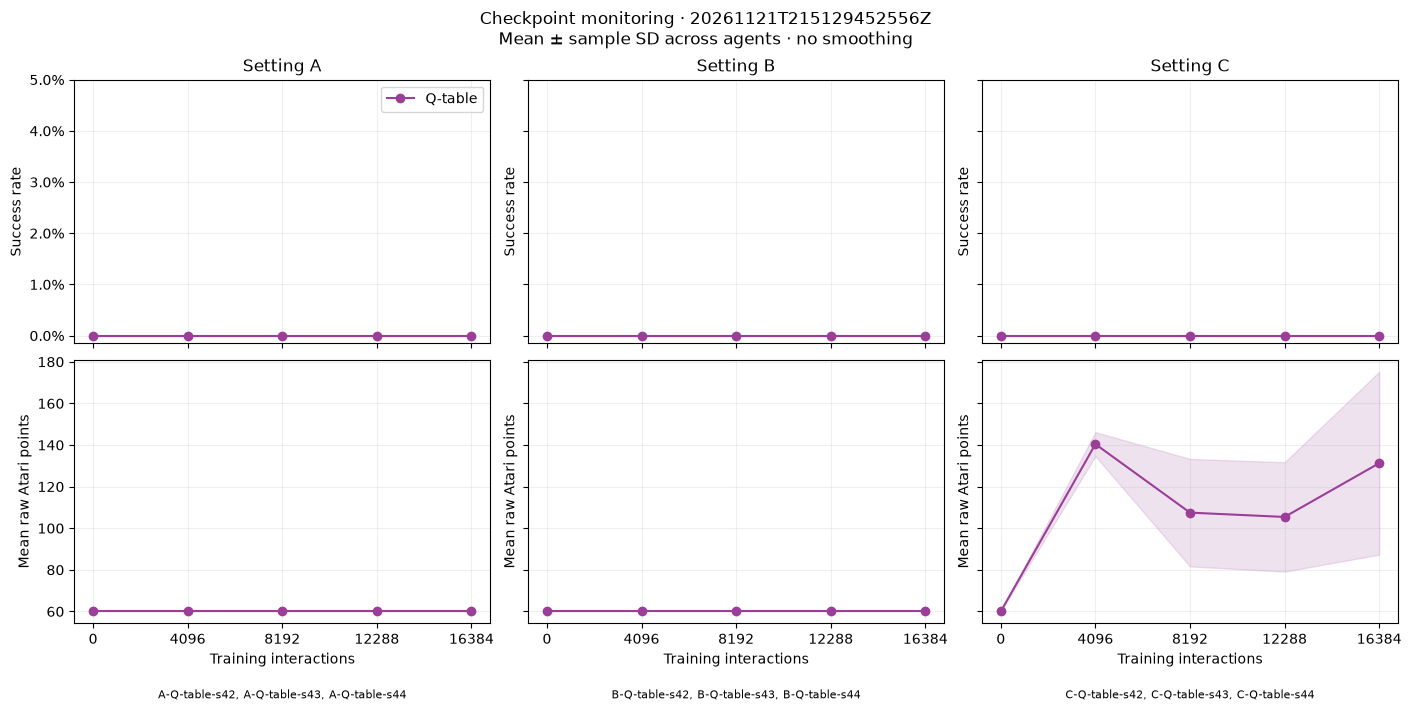

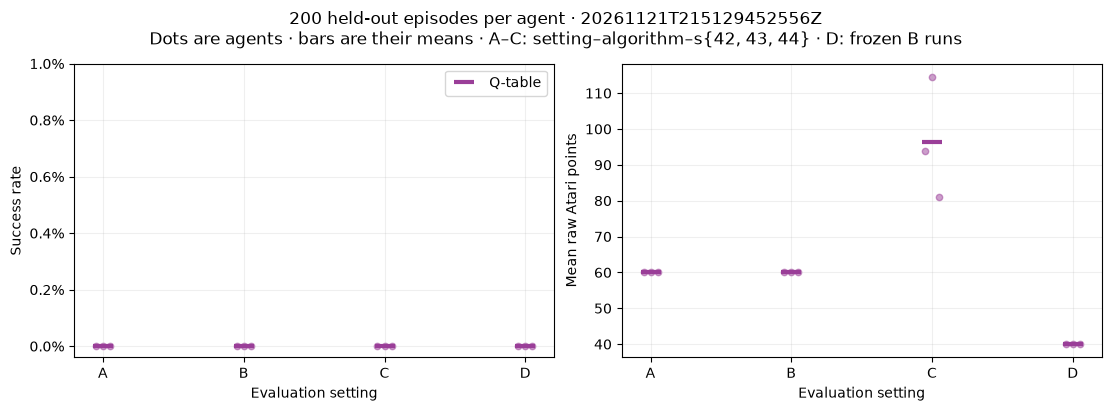

In [10]:
from matplotlib.ticker import PercentFormatter

COLORS = {"Q-table": "#9a3e98", "DQN": "#176d8c", "PPO": "#b25217"}
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey="row", layout="constrained")
success_stats = learning.groupby(["setting", "algorithm", "interactions"])["success_rate"]
success_ceiling = max(0.05, min(1.0, 1.1 * (success_stats.mean() + success_stats.std()).max()))
for col, setting in enumerate(("A", "B", "C")):
    subset = learning[learning["setting"] == setting]
    for row, (metric, label) in enumerate((("success_rate", "Success rate"),
                                          ("mean_raw_score", "Mean raw Atari points"))):
        ax = axes[row, col]
        for algorithm, group in subset.groupby("algorithm"):
            checkpoints_by_step = group.groupby("interactions")[metric]
            mean = checkpoints_by_step.mean()
            sd = checkpoints_by_step.std(ddof=1).fillna(0)
            ax.plot(mean.index, mean, marker="o", color=COLORS[algorithm], label=algorithm)
            low, high = mean - sd, mean + sd
            ax.fill_between(mean.index, low.clip(lower=0),
                            high.clip(upper=1) if metric == "success_rate" else high,
                            color=COLORS[algorithm], alpha=0.15)
        ax.set_ylabel(label)
        ax.grid(alpha=0.2)
        if row == 0:
            ax.set_ylim(-0.03 * success_ceiling, success_ceiling)
            ax.yaxis.set_major_formatter(PercentFormatter(1))
            ax.set_title(f"Setting {setting}")
        else:
            ax.set_xlabel("Training interactions")
            ids = [", ".join(group["run_id"].unique()) for _, group in subset.groupby("algorithm")]
            ax.text(0.5, -0.25, "\n".join(ids), ha="center", va="top", fontsize=8, transform=ax.transAxes)
axes[1, 0].set_xticks(sorted(learning["interactions"].unique()))
axes[0, 0].legend()
fig.suptitle(f"Checkpoint monitoring · {OUTPUT.name}\nMean ± sample SD across agents · no smoothing")
fig.savefig(OUTPUT / "learning_curves.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
positions = np.arange(4)
for ax, (metric, label) in zip(axes, (("success_rate", "Success rate"),
                                    ("mean_raw_score", "Mean raw Atari points"))):
    shifts = np.linspace(-0.19, 0.19, len(ALGORITHMS)) if len(ALGORITHMS) > 1 else [0.0]
    for algorithm, shift in zip(ALGORITHMS, shifts):
        algorithm_rows = per_agent[per_agent["algorithm"] == algorithm]
        for i, setting in enumerate(("A", "B", "C", "D")):
            values = algorithm_rows[algorithm_rows["setting"] == setting][metric]
            ax.scatter(i + shift + np.linspace(-0.05, 0.05, len(values)), values,
                       color=COLORS[algorithm], alpha=0.5, s=21)
        ax.plot(positions + shift, means.xs(algorithm, level="algorithm")[metric], "_",
                color=COLORS[algorithm], ms=15, mew=3, label=algorithm)
    ax.set(xticks=positions, xticklabels=["A", "B", "C", "D"], ylabel=label, xlabel="Evaluation setting")
    ax.grid(alpha=0.2)
success_ceiling = max(0.01, min(1.0, 1.2 * per_agent["success_rate"].max()))
axes[0].set_ylim(-0.04 * success_ceiling, success_ceiling)
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
axes[0].legend()
source_ids = f"A–C: setting–algorithm–s{{{', '.join(map(str, TRAINING_SEEDS))}}} · D: frozen B runs"
fig.suptitle(f"{len(TEST_SEEDS)} held-out episodes per agent · {OUTPUT.name}\n"
             f"Dots are agents · bars are their means · {source_ids}")
fig.savefig(OUTPUT / "held_out_results.png", dpi=160)
plt.show()

## Inspect a recorded episode

`replay_episode` reconstructs a held-out episode from its explicit action sequence. It verifies the recorded outcome and score and returns the observations, chosen actions, Q-values or policy probabilities, reward, and lives. For transfer episodes use the B agent ID and pass `"D"` as the evaluation setting.

In [ ]:
@torch.inference_mode()
def replay_episode(run_id, setting, eval_seed, output=OUTPUT):
    folder = Path(output) / run_id
    run = json.loads((folder / "run.json").read_text(encoding="utf-8"))
    algorithm = run["algorithm"]
    model = load_model(algorithm, Path(output) / run["checkpoint"])
    with gzip.open(folder / f"actions_{setting}.jsonl.gz", "rt", encoding="utf-8") as stream:
        episodes = map(json.loads, stream)
        trace = next(row for row in episodes if row["eval_seed"] == eval_seed)
    episode = pd.read_csv(folder / f"evaluation_{setting}.csv").set_index("eval_seed").loc[eval_seed]

    decisions, frames = [], []
    with build_environment(setting) as env:
        obs, info = env.reset(seed=eval_seed)
        for step, action in enumerate(trace["actions"], 1):
            frames.append(obs.copy())
            if algorithm == "Q-table":
                state = tabular_state(env.unwrapped.ale.getRAM())
                outputs = dict(state_key=state, seen_in_training=state in model.q,
                               q_values=model.values(state).tolist())
            elif algorithm == "DQN":
                outputs = dict(q_values=model(tensor(obs[None]))[0].tolist())
            else:
                logits, _ = model(tensor(obs[None]))
                outputs = dict(probabilities=logits.softmax(dim=1)[0].tolist())
            lives_before = info["lives"]
            obs, reward, terminated, truncated, info = env.step(action)
            decisions.append(dict(step=step, action=ACTION_NAMES[action], reward=reward,
                                  raw_points=info["raw_points"], raw_score=info["raw_score"],
                                  lives_before=lives_before, lives_after=info["lives"],
                                  outcome=info["outcome"], **outputs))
        frames.append(obs.copy())
    assert terminated or truncated
    assert len(decisions) == episode["length"]
    assert info["outcome"] == episode["outcome"] and info["raw_score"] == episode["raw_score"]
    assert np.isclose(sum(row["reward"] for row in decisions), episode["episode_return"])
    return pd.DataFrame(decisions), np.stack(frames)

: 

## Record of AI assistance

Codex added the tabular state encoder and training loop and connected them to the original experiment and dashboard output. The team runs and verifies training and evaluation. Record any accepted or revised implementation choices in the submission.